# Workshop 3 – Fashion-MNIST with a feed-forward network

Fashion-MNIST: 60,000 training and 10,000 test images, 28×28 grayscale, 10 clothing categories.

The approach mirrors the `MNIST Feedforward.ipynb` example: flatten → scale → one-hot labels → Dense network → RMSprop → evaluate on the test set.

## 1. Load Fashion-MNIST

STEP 1 is to import the dataset 

The Fashion MNIST data set is a similar data set.  
    10 categories of fashion items | 60,000 training and 10,000 testing examples
    each example consists of a 28x28 grayscale image and its category

In [1]:
%pip install tensorflow keras
from keras.datasets import fashion_mnist

Note: you may need to restart the kernel to use updated packages.


In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()


In [3]:
print("x_train shape", x_train.shape)
print("y_train shape", y_train.shape)
print("x_test shape ", x_test.shape)
print("y_test shape ", y_test.shape)

x_train shape (60000, 28, 28)
y_train shape (60000,)
x_test shape  (10000, 28, 28)
y_test shape  (10000,)


Labels are integers 0–9. The category names (from the Fashion-MNIST documentation) are listed below, and a few examples are shown to check the data looks right.

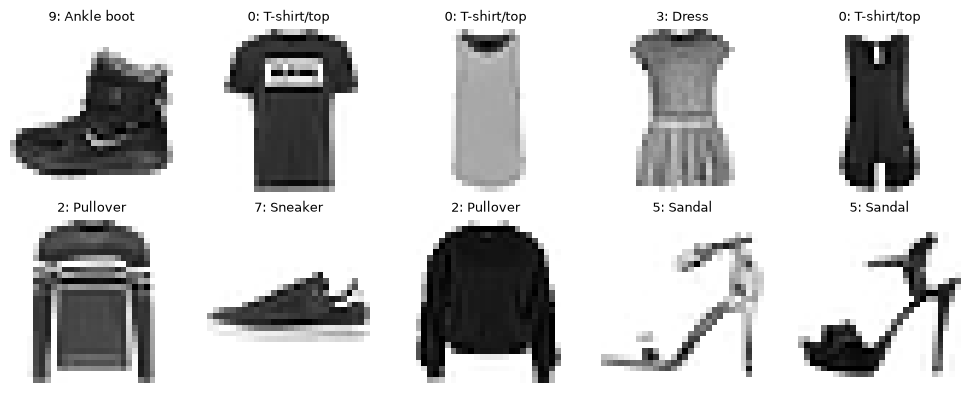

In [4]:
import matplotlib.pyplot as plt

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Show the first 10 training images with their category names
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap=plt.cm.binary)
    plt.title(f"{y_train[i]}: {class_names[y_train[i]]}", fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Prepare the data

Same preprocessing as the MNIST example:

- flatten each 28×28 image into a vector of 784 values
- scale pixel values from 0–255 to 0–1 (as `float32`)
- one-hot encode the labels with `to_categorical`, because the network ends in a 10-way softmax trained with `categorical_crossentropy`

The raw `x_train` / `y_train` arrays are left unchanged, so these cells can be re-run safely.

In [5]:
# Flatten 28x28 -> 784 and scale 0-255 -> 0-1
train_images = x_train.reshape((60000, 28*28)).astype('float32') / 255
test_images  = x_test.reshape((10000, 28*28)).astype('float32') / 255

print("train_images shape", train_images.shape)
print("test_images shape ", test_images.shape)
print("pixel range", train_images.min(), "to", train_images.max())

train_images shape (60000, 784)
test_images shape  (10000, 784)
pixel range 0.0 to 1.0


In [6]:
# One-hot encode the labels
from keras.utils import to_categorical

print("train label shape before", y_train.shape)
train_labels = to_categorical(y_train)
test_labels  = to_categorical(y_test)
print("train label shape after ", train_labels.shape)

print("example label", y_train[0], "->", train_labels[0])

train label shape before (60000,)
train label shape after  (60000, 10)
example label 9 -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


## 3. Baseline feed-forward network

Same architecture as the MNIST example: **784 inputs → Dense(512, ReLU) → Dense(10, softmax)**.

Compiled with RMSprop (default learning rate 0.001), categorical cross-entropy loss and accuracy metric; trained for 5 epochs with batch size 128.

In [7]:
from keras import models
from keras import layers

# Define the network
network = models.Sequential()
network.add(layers.Input(shape=(28*28,)))        # Keras 3 input layer (replaces input_shape=... on the first Dense)
network.add(layers.Dense(512, activation='relu'))
network.add(layers.Dense(10, activation='softmax'))

network.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Compile the network
network.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])

In [9]:
# Train the network
history = network.fit(train_images, train_labels, epochs=5, batch_size=128)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7990 - loss: 0.5671
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8582 - loss: 0.3874
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8751 - loss: 0.3402
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8847 - loss: 0.3127
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8926 - loss: 0.2939


In [10]:
# Evaluate on the test set
test_loss, test_acc = network.evaluate(test_images, test_labels)
print(f"\nBaseline test loss:     {test_loss:.4f}")
print(f"Baseline test accuracy: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 430us/step - accuracy: 0.8582 - loss: 0.3889

Baseline test loss:     0.3889
Baseline test accuracy: 0.8582


## 4. Experiments

Controlled experiments that change **one factor at a time** from the baseline (1 hidden layer of 512 units, ReLU, 5 epochs, RMSprop learning rate 0.001).

A helper function builds, trains and evaluates each variant with the same random seed and batch size so the results are comparable.

| Experiment | What changes |
|---|---|
| A | Baseline (reference point) |
| B | Number of hidden layers: 2 (512 → 256) instead of 1 |
| C | Hidden activation: tanh instead of ReLU |
| D | Epochs: 15 instead of 5 |
| E | RMSprop learning rate: 0.005 (workshop example) and 0.0001 instead of 0.001 |

In [11]:
import keras

def run_experiment(name, hidden_layers=(512,), activation='relu', epochs=5, learning_rate=0.001):
    """Build, train and evaluate a feed-forward network. Returns a dict of settings and results."""
    keras.utils.set_random_seed(42)   # same initial weights / shuffling for every experiment

    model = models.Sequential()
    model.add(layers.Input(shape=(28*28,)))
    for units in hidden_layers:
        model.add(layers.Dense(units, activation=activation))
    model.add(layers.Dense(10, activation='softmax'))

    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=learning_rate),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(train_images, train_labels, epochs=epochs, batch_size=128, verbose=0)
    test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)

    result = {
        'Experiment': name,
        'Hidden layers': f"{len(hidden_layers)} ({', '.join(str(u) for u in hidden_layers)})",
        'Activation': activation,
        'Epochs': epochs,
        'Learning rate': learning_rate,
        'Train accuracy': history.history['accuracy'][-1],
        'Test accuracy': test_acc,
        'Test loss': test_loss,
    }
    print(f"{name:<26} train acc {result['Train accuracy']:.4f} | "
          f"test acc {test_acc:.4f} | test loss {test_loss:.4f}")
    return result

results = {}   # keyed by experiment letter so re-running a cell just overwrites that entry

In [12]:
# Experiment A – baseline (1 hidden layer of 512, ReLU, 5 epochs, learning rate 0.001)
results['A'] = run_experiment('A: baseline')

A: baseline                train acc 0.8925 | test acc 0.8741 | test loss 0.3519


In [13]:
# Experiment B – more hidden layers (512 -> 256)
results['B'] = run_experiment('B: 2 hidden layers', hidden_layers=(512, 256))

B: 2 hidden layers         train acc 0.8950 | test acc 0.8786 | test loss 0.3573


In [14]:
# Experiment C – different hidden activation function
results['C'] = run_experiment('C: tanh activation', activation='tanh')

C: tanh activation         train acc 0.8788 | test acc 0.8607 | test loss 0.3847


In [15]:
# Experiment D – more epochs
results['D'] = run_experiment('D: 15 epochs', epochs=15)

D: 15 epochs               train acc 0.9328 | test acc 0.8699 | test loss 0.4222


In [16]:
# Experiment E – different RMSprop learning rates (default is 0.001)
results['E1'] = run_experiment('E1: learning rate 0.005', learning_rate=0.005)
results['E2'] = run_experiment('E2: learning rate 0.0001', learning_rate=0.0001)

E1: learning rate 0.005    train acc 0.8823 | test acc 0.8635 | test loss 0.4051
E2: learning rate 0.0001   train acc 0.8654 | test acc 0.8492 | test loss 0.4294


## 5. Results comparison

In [17]:
from IPython.display import Markdown, display

header = "| Experiment | Hidden layers | Activation | Epochs | Learning rate | Train accuracy | Test accuracy | Test loss |"
sep    = "|---|---|---|---|---|---|---|---|"
rows = [
    f"| {r['Experiment']} | {r['Hidden layers']} | {r['Activation']} | {r['Epochs']} | {r['Learning rate']} "
    f"| {r['Train accuracy']:.4f} | {r['Test accuracy']:.4f} | {r['Test loss']:.4f} |"
    for r in results.values()
]
display(Markdown("\n".join([header, sep] + rows)))

| Experiment | Hidden layers | Activation | Epochs | Learning rate | Train accuracy | Test accuracy | Test loss |
|---|---|---|---|---|---|---|---|
| A: baseline | 1 (512) | relu | 5 | 0.001 | 0.8925 | 0.8741 | 0.3519 |
| B: 2 hidden layers | 2 (512, 256) | relu | 5 | 0.001 | 0.8950 | 0.8786 | 0.3573 |
| C: tanh activation | 1 (512) | tanh | 5 | 0.001 | 0.8788 | 0.8607 | 0.3847 |
| D: 15 epochs | 1 (512) | relu | 15 | 0.001 | 0.9328 | 0.8699 | 0.4222 |
| E1: learning rate 0.005 | 1 (512) | relu | 5 | 0.005 | 0.8823 | 0.8635 | 0.4051 |
| E2: learning rate 0.0001 | 1 (512) | relu | 5 | 0.0001 | 0.8654 | 0.8492 | 0.4294 |

## 6. Observations

- **Baseline:** 784 → Dense(512, ReLU) → Dense(10, softmax) reaches ~86–87% test accuracy on Fashion-MNIST, far below the ~98% the same network gets on MNIST digits. Clothing categories (shirt vs T-shirt vs pullover) are much harder to separate than digits.
- **Run-to-run variation is ~1–2%** (unseeded Section 3 baseline 85.8% vs seeded Experiment A 87.4%), so differences smaller than that between experiments are not conclusive.
- **B – extra hidden layer:** small gain (87.9% vs 87.4%) for ~130k extra parameters. Extra depth in a plain dense network is not clearly worth it here.
- **C – tanh:** slightly worse than ReLU (86.1%) and trains more slowly. ReLU stays the better default.
- **D – 15 epochs:** training accuracy climbs to 93% but test accuracy stays ~87% and test *loss rises* (0.42 vs 0.35): classic overfitting. More epochs alone do not help without regularisation / early stopping.
- **E – learning rate:** 0.005 is too high (noisier training, 86.4%); 0.0001 is too low to converge in 5 epochs (84.9%). The default 0.001 was best.
- **Overall:** this feed-forward design plateaus around 87–88%. Tweaking layers, activation, epochs or learning rate changes little, so bigger gains need a different model type (e.g. convolutional layers) rather than more dense layers or epochs.